In [143]:
import numpy as np
import pandas as pd
import random

import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns

In [144]:
df = pd.DataFrame(
    [
        [6.82, 118, 0],
        [6.36, 125, 1],
        [5.39, 99, 1],
        [5.50, 106, 1],
        [6.39, 148, 0],
        [9.13, 148, 1],
        [7.17, 147, 1],
        [7.72, 72, 0]
    ],
    columns = ['cgpa', 'iq', 'is_placed']
)

In [145]:
df

,cgpa,iq,is_placed
0,6.82,118,0
1,6.36,125,1
2,5.39,99,1
3,5.50,106,1
4,6.39,148,0
5,9.13,148,1
6,7.17,147,1
7,7.72,72,0


In [146]:
# Initail prediction - first model
df['pred1(log_odds)'] = np.log(df[df['is_placed']== 1].shape[0]/df[df['is_placed']== 0].shape[0])
df

,cgpa,iq,is_placed,pred1(log_odds)
0,6.82,118,0,0.510826
1,6.36,125,1,0.510826
2,5.39,99,1,0.510826
3,5.50,106,1,0.510826
4,6.39,148,0,0.510826
5,9.13,148,1,0.510826
6,7.17,147,1,0.510826
7,7.72,72,0,0.510826


In [147]:
# Convert log-odds into probability
df['pred1(probability)'] = 1/(1 + np.exp(-df['pred1(log_odds)']))
df

,cgpa,iq,is_placed,pred1(log_odds),pred1(probability)
0,6.82,118,0,0.510826,0.625
1,6.36,125,1,0.510826,0.625
2,5.39,99,1,0.510826,0.625
3,5.50,106,1,0.510826,0.625
4,6.39,148,0,0.510826,0.625
5,9.13,148,1,0.510826,0.625
6,7.17,147,1,0.510826,0.625
7,7.72,72,0,0.510826,0.625


In [148]:
# Calculate the residuals
df['res1'] = df['is_placed'] - df['pred1(probability)']
df

,cgpa,iq,is_placed,pred1(log_odds),pred1(probability),res1
0,6.82,118,0,0.510826,0.625,-0.625
1,6.36,125,1,0.510826,0.625,0.375
2,5.39,99,1,0.510826,0.625,0.375
3,5.50,106,1,0.510826,0.625,0.375
4,6.39,148,0,0.510826,0.625,-0.625
5,9.13,148,1,0.510826,0.625,0.375
6,7.17,147,1,0.510826,0.625,0.375
7,7.72,72,0,0.510826,0.625,-0.625


In [149]:
# Second model - DecisionTreeRegressor
from sklearn.tree import DecisionTreeRegressor, plot_tree
model2 = DecisionTreeRegressor(max_leaf_nodes=3, random_state = 42)
model2.fit(df[['cgpa', 'iq']], df['res1'])

DecisionTreeRegressor(max_leaf_nodes=3, random_state=42)

[Text(0.4, 0.8333333333333334, 'node #0\ncgpa <= 6.375\nsquared_error = 0.234\nsamples = 8\nvalue = 0.0'),
 Text(0.2, 0.5, 'node #1\nsquared_error = 0.0\nsamples = 3\nvalue = 0.375'),
 Text(0.30000000000000004, 0.6666666666666667, 'True  '),
 Text(0.6, 0.5, 'node #2\niq <= 132.5\nsquared_error = 0.24\nsamples = 5\nvalue = -0.225'),
 Text(0.5, 0.6666666666666667, '  False'),
 Text(0.4, 0.16666666666666666, 'node #3\nsquared_error = 0.0\nsamples = 2\nvalue = -0.625'),
 Text(0.8, 0.16666666666666666, 'node #4\nsquared_error = 0.222\nsamples = 3\nvalue = 0.042')]

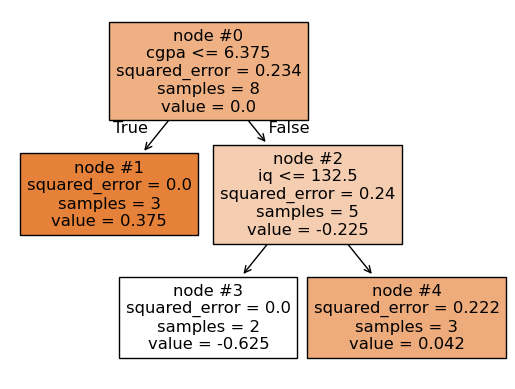

In [150]:
plot_tree(model2, feature_names=['cgpa','iq'], filled=True, node_ids=True)

In [151]:
df['leaf_entry1'] = model2.apply(df[['cgpa', 'iq']])
df

,cgpa,iq,is_placed,pred1(log_odds),pred1(probability),res1,leaf_entry1
0,6.82,118,0,0.510826,0.625,-0.625,3
1,6.36,125,1,0.510826,0.625,0.375,1
2,5.39,99,1,0.510826,0.625,0.375,1
3,5.50,106,1,0.510826,0.625,0.375,1
4,6.39,148,0,0.510826,0.625,-0.625,4
5,9.13,148,1,0.510826,0.625,0.375,4
6,7.17,147,1,0.510826,0.625,0.375,4
7,7.72,72,0,0.510826,0.625,-0.625,3


In [152]:
# Log-odds for wrong predicted samples
def return_logs(leaf):
  temp_df = df[df['leaf_entry1'] == leaf]

  numerator = temp_df['res1'].sum()
  denominator = sum(temp_df['pred1(probability)']*(1 - temp_df['pred1(probability)']))

  return round(numerator/denominator, 3)

In [153]:
df['pred2(log_odds)'] = df['pred1(log_odds)'] + df['leaf_entry1'].apply(return_logs)
df

,cgpa,iq,is_placed,pred1(log_odds),pred1(probability),res1,leaf_entry1,pred2(log_odds)
0,6.82,118,0,0.510826,0.625,-0.625,3,-2.156174
1,6.36,125,1,0.510826,0.625,0.375,1,2.110826
2,5.39,99,1,0.510826,0.625,0.375,1,2.110826
3,5.50,106,1,0.510826,0.625,0.375,1,2.110826
4,6.39,148,0,0.510826,0.625,-0.625,4,0.688826
5,9.13,148,1,0.510826,0.625,0.375,4,0.688826
6,7.17,147,1,0.510826,0.625,0.375,4,0.688826
7,7.72,72,0,0.510826,0.625,-0.625,3,-2.156174


In [154]:
# Convert into probability
df['pred2(probability)'] = 1/(1 + np.exp(-df['pred2(log_odds)']))
df

,cgpa,iq,is_placed,pred1(log_odds),pred1(probability),res1,leaf_entry1,pred2(log_odds),pred2(probability)
0,6.82,118,0,0.510826,0.625,-0.625,3,-2.156174,0.103756
1,6.36,125,1,0.510826,0.625,0.375,1,2.110826,0.891951
2,5.39,99,1,0.510826,0.625,0.375,1,2.110826,0.891951
3,5.50,106,1,0.510826,0.625,0.375,1,2.110826,0.891951
4,6.39,148,0,0.510826,0.625,-0.625,4,0.688826,0.665706
5,9.13,148,1,0.510826,0.625,0.375,4,0.688826,0.665706
6,7.17,147,1,0.510826,0.625,0.375,4,0.688826,0.665706
7,7.72,72,0,0.510826,0.625,-0.625,3,-2.156174,0.103756


In [155]:
# Calculate the residuals
df['res2'] = df['is_placed'] - df['pred2(probability)']
df

,cgpa,iq,is_placed,pred1(log_odds),pred1(probability),res1,leaf_entry1,pred2(log_odds),pred2(probability),res2
0,6.82,118,0,0.510826,0.625,-0.625,3,-2.156174,0.103756,-0.103756
1,6.36,125,1,0.510826,0.625,0.375,1,2.110826,0.891951,0.108049
2,5.39,99,1,0.510826,0.625,0.375,1,2.110826,0.891951,0.108049
3,5.50,106,1,0.510826,0.625,0.375,1,2.110826,0.891951,0.108049
4,6.39,148,0,0.510826,0.625,-0.625,4,0.688826,0.665706,-0.665706
5,9.13,148,1,0.510826,0.625,0.375,4,0.688826,0.665706,0.334294
6,7.17,147,1,0.510826,0.625,0.375,4,0.688826,0.665706,0.334294
7,7.72,72,0,0.510826,0.625,-0.625,3,-2.156174,0.103756,-0.103756


In [156]:
# Third model
model3 = DecisionTreeRegressor(max_leaf_nodes=3, random_state = 42)
model3.fit(df[['cgpa', 'iq']], df['res2'])

DecisionTreeRegressor(max_leaf_nodes=3, random_state=42)

[Text(0.6, 0.8333333333333334, 'node #0\ncgpa <= 6.995\nsquared_error = 0.09\nsamples = 8\nvalue = 0.015'),
 Text(0.4, 0.5, 'node #1\niq <= 136.5\nsquared_error = 0.09\nsamples = 5\nvalue = -0.089'),
 Text(0.5, 0.6666666666666667, 'True  '),
 Text(0.2, 0.16666666666666666, 'node #3\nsquared_error = 0.008\nsamples = 4\nvalue = 0.055'),
 Text(0.6, 0.16666666666666666, 'node #4\nsquared_error = -0.0\nsamples = 1\nvalue = -0.666'),
 Text(0.8, 0.5, 'node #2\nsquared_error = 0.043\nsamples = 3\nvalue = 0.188'),
 Text(0.7, 0.6666666666666667, '  False')]

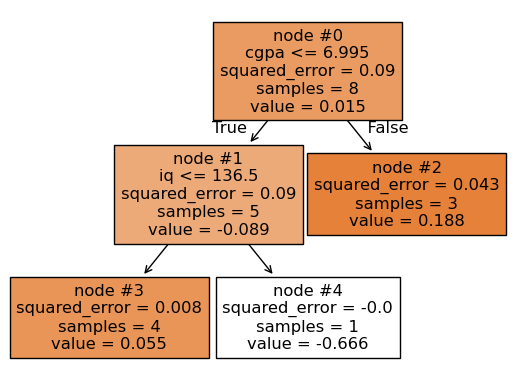

In [157]:
plot_tree(model3, feature_names=['cgpa','iq'], filled=True, node_ids=True)

In [158]:
df['leaf_entry2'] = model3.apply(df[['cgpa', 'iq']])

In [159]:
def return_logs(leaf):
  num = df[df['leaf_entry2'] == leaf]['res2'].sum()
  den = sum(df[df['leaf_entry2'] == leaf]['pred2(probability)'] * (1 - df[df['leaf_entry2'] == leaf]['pred2(probability)']))
  return round(num/den,2)

In [160]:
df.head()

,cgpa,iq,is_placed,pred1(log_odds),pred1(probability),res1,leaf_entry1,pred2(log_odds),pred2(probability),res2,leaf_entry2
0,6.82,118,0,0.510826,0.625,-0.625,3,-2.156174,0.103756,-0.103756,3
1,6.36,125,1,0.510826,0.625,0.375,1,2.110826,0.891951,0.108049,3
2,5.39,99,1,0.510826,0.625,0.375,1,2.110826,0.891951,0.108049,3
3,5.50,106,1,0.510826,0.625,0.375,1,2.110826,0.891951,0.108049,3
4,6.39,148,0,0.510826,0.625,-0.625,4,0.688826,0.665706,-0.665706,4


In [161]:
df['pred3(log_odds)'] = df['pred1(log_odds)'] + df['pred2(log_odds)'] + df['leaf_entry2'].apply(return_logs)

In [162]:
df['pred3(probability)'] = 1/(1+np.exp(-df['pred2(log_odds)']))
df

,cgpa,iq,is_placed,pred1(log_odds),pred1(probability),res1,leaf_entry1,pred2(log_odds),pred2(probability),res2,leaf_entry2,pred3(log_odds),pred3(probability)
0,6.82,118,0,0.510826,0.625,-0.625,3,-2.156174,0.103756,-0.103756,3,-1.065349,0.103756
1,6.36,125,1,0.510826,0.625,0.375,1,2.110826,0.891951,0.108049,3,3.201651,0.891951
2,5.39,99,1,0.510826,0.625,0.375,1,2.110826,0.891951,0.108049,3,3.201651,0.891951
3,5.50,106,1,0.510826,0.625,0.375,1,2.110826,0.891951,0.108049,3,3.201651,0.891951
4,6.39,148,0,0.510826,0.625,-0.625,4,0.688826,0.665706,-0.665706,4,-1.790349,0.665706
5,9.13,148,1,0.510826,0.625,0.375,4,0.688826,0.665706,0.334294,2,2.249651,0.665706
6,7.17,147,1,0.510826,0.625,0.375,4,0.688826,0.665706,0.334294,2,2.249651,0.665706
7,7.72,72,0,0.510826,0.625,-0.625,3,-2.156174,0.103756,-0.103756,2,-0.595349,0.103756


In [163]:
df['res_final'] = df['is_placed'] - df['pred3(probability)']

df[['res1','res2','res_final']]

,res1,res2,res_final
0,-0.625,-0.103756,-0.103756
1,0.375,0.108049,0.108049
2,0.375,0.108049,0.108049
3,0.375,0.108049,0.108049
4,-0.625,-0.665706,-0.665706
5,0.375,0.334294,0.334294
6,0.375,0.334294,0.334294
7,-0.625,-0.103756,-0.103756


In [164]:
df.head()

,cgpa,iq,is_placed,pred1(log_odds),pred1(probability),res1,leaf_entry1,pred2(log_odds),pred2(probability),res2,leaf_entry2,pred3(log_odds),pred3(probability),res_final
0,6.82,118,0,0.510826,0.625,-0.625,3,-2.156174,0.103756,-0.103756,3,-1.065349,0.103756,-0.103756
1,6.36,125,1,0.510826,0.625,0.375,1,2.110826,0.891951,0.108049,3,3.201651,0.891951,0.108049
2,5.39,99,1,0.510826,0.625,0.375,1,2.110826,0.891951,0.108049,3,3.201651,0.891951,0.108049
3,5.50,106,1,0.510826,0.625,0.375,1,2.110826,0.891951,0.108049,3,3.201651,0.891951,0.108049
4,6.39,148,0,0.510826,0.625,-0.625,4,0.688826,0.665706,-0.665706,4,-1.790349,0.665706,-0.665706


In [165]:
# Preditc
def predict(cgpa, iq):
  pred1 = np.log(df[df['is_placed']== 1].shape[0]/df[df['is_placed']== 0].shape[0])
  pred2 = pred1 + model2.predict([[cgpa, iq]])[0]
  pred3 = pred2 + model3.predict([[cgpa, iq]])[0]
  return 1/(1 + np.exp(-pred3))

In [169]:
predict(5.50,	106)

np.float64(0.7192861649870522)